# Step 04: Interactive Hyperparameter Tuning, Multi-Run Evaluation & Epoch Ablation

Provides an easy-to-adjust control panel to experiment with hyperparameters (`REPRESENTATION`, `epochs`, `lr`, `batch_size`, `num_runs`, `use_wandb`), run multi-seed experiments to eliminate single-run chance, auto-export benchmark artifacts, and conduct epoch ablation studies to test if increasing training epochs improves model convergence.


In [7]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root_dir = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root_dir) not in sys.path: sys.path.insert(0, str(root_dir))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.train_loso import run_loso_cross_validation
sns.set_theme(style="whitegrid")

# ==============================================================================
# EASY HYPERPARAMETER ADJUSTMENT PANEL
# ==============================================================================
REPRESENTATION = "rep2_projections"  # Options: 'rep1_doppler', 'rep2_projections', 'rep3_pointset'
epochs = 30                      # Number of training epochs per fold (e.g. 10, 20, 30, 40)
lr = 5e-5                        # Learning rate (Adam optimizer)
batch_size = 16                  # Mini-batch size
num_runs = 3                     # Number of random seeds to evaluate (eliminates luck)
use_wandb = False                # Set to True to log metrics to Weights & Biases

print(f"Selected Representation: '{REPRESENTATION}'")
print(f"Selected Hyperparameters: epochs={epochs}, lr={lr}, batch_size={batch_size}, num_runs={num_runs}, use_wandb={use_wandb}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Selected Representation: 'rep2_projections'
Selected Hyperparameters: epochs=30, lr=5e-05, batch_size=16, num_runs=3, use_wandb=False


In [8]:
# Execute Experiment with Custom Hyperparameters & Multi-Run Averaging
ablation_json_path = Path(f"models/benchmarks/ablation_{REPRESENTATION}_{epochs}ep_benchmark.json")
res = run_loso_cross_validation(
    rep_key=REPRESENTATION,
    epochs=epochs,
    lr=lr,
    batch_size=batch_size,
    num_runs=num_runs,
    use_wandb=use_wandb,
    save_benchmark=True,
    output_json_path=ablation_json_path
)
test_m = res["test_metrics"]

print(f"\n=== Held-Out Test Experiment Results ('{REPRESENTATION}', {num_runs} Runs Mean ± Std) ===")
print(f"Test Accuracy:   {test_m['accuracy']*100:.2f}% ± {test_m['accuracy_std']*100:.2f}%")
print(f"Test Recall:     {test_m['recall']*100:.2f}% ± {test_m['recall_std']*100:.2f}%")
print(f"Test Precision:  {test_m['precision']*100:.2f}% ± {test_m['precision_std']*100:.2f}%")
print(f"Test Macro F1:   {test_m['macro_f1']*100:.2f}% ± {test_m['macro_f1_std']*100:.2f}%")
print(f"Test ROC-AUC:    {test_m['roc_auc']:.4f} ± {test_m['roc_auc_std']:.4f}")
print(f"Test FPR:        {test_m['fpr']*100:.2f}% ± {test_m['fpr_std']*100:.2f}%")
print(f"Exported ablation benchmark JSON to: {ablation_json_path}")



Starting LOSO Cross-Validation for Representation: rep2_projections
Runs: 3 | Seeds: [42, 52, 62] | Epochs: 30 | LR: 5e-05 | Batch Size: 16

>>> Starting Run 1/3 (Seed: 42) <<<
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/30] Train Loss: 0.1071, Train Acc: 100.00%
  Epoch [10/30] Train Loss: 0.0285, Train Acc: 100.00%
  Epoch [15/30] Train Loss: 0.0157, Train Acc: 100.00%
  Epoch [20/30] Train Loss: 0.0069, Train Acc: 100.00%
  Epoch [25/30] Train Loss: 0.0044, Train Acc: 100.00%
  Epoch [30/30] Train Loss: 0.0047, Train Acc: 100.00%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/30] Train Loss: 0.0997, Train Acc: 98.62%
  Epoch [10/30] Train Loss: 0.0344, Train Acc: 100.00%
  Epoch [15/30] Train Loss: 0.0106, Train Acc: 100.00%
  Epoch [20/30] Train Loss: 0.0084, Train Acc: 100.00%
  Epoch [25/30] Train Loss: 0.0034, Train Acc: 100.00%
  Epoch [30/30] Train Loss: 0.0036

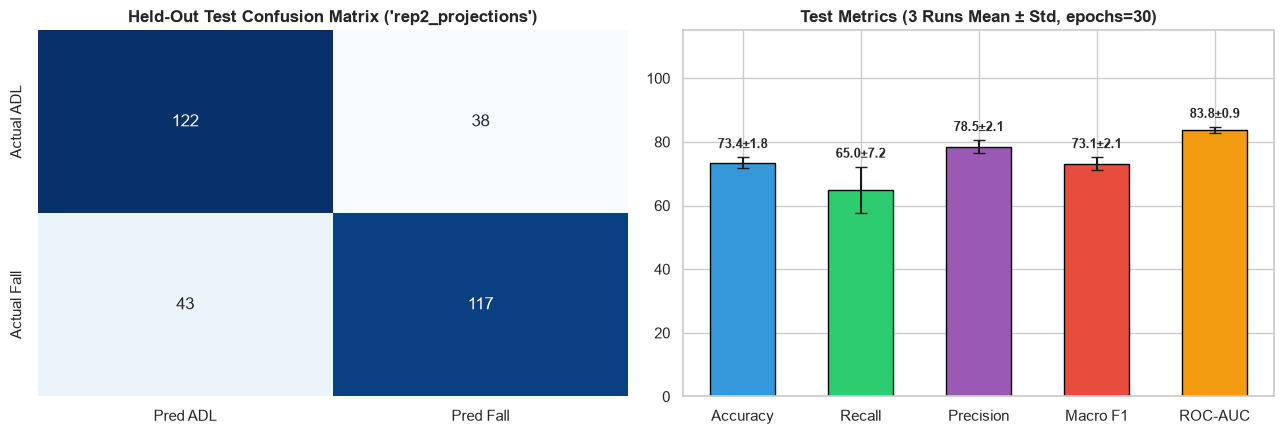

In [9]:
# Plot Custom Experiment Confusion Matrix & Metric Breakdown with Error Bars
cm_matrix = np.array(test_m["confusion_matrix"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)

sns.heatmap(cm_matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Pred ADL", "Pred Fall"], yticklabels=["Actual ADL", "Actual Fall"])
axes[0].set_title(f"Held-Out Test Confusion Matrix ('{REPRESENTATION}')", fontweight="bold")

metrics = ["Accuracy", "Recall", "Precision", "Macro F1", "ROC-AUC"]
vals = [test_m["accuracy"]*100, test_m["recall"]*100, test_m["precision"]*100, test_m["macro_f1"]*100, test_m["roc_auc"]*100]
stds = [test_m["accuracy_std"]*100, test_m["recall_std"]*100, test_m["precision_std"]*100, test_m["macro_f1_std"]*100, test_m["roc_auc_std"]*100]
colors = ["#3498db", "#2ecc71", "#9b59b6", "#e74c3c", "#f39c12"]

bars = axes[1].bar(metrics, vals, yerr=stds, capsize=4, color=colors, edgecolor="black", width=0.55)
axes[1].set_ylim(0, 115)
axes[1].set_title(f"Test Metrics ({num_runs} Runs Mean ± Std, epochs={epochs})", fontweight="bold")
for bar, std in zip(bars, stds):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., h + std + 2, f"{h:.1f}±{std:.1f}", ha="center", va="bottom", fontweight="bold", fontsize=9)

plt.tight_layout()
plt.show()



=== Starting Epoch Ablation Study for Representation: 'rep2_projections' ===

---> Evaluating Epoch Count = 10 (num_runs=3) <---

Starting LOSO Cross-Validation for Representation: rep2_projections
Runs: 3 | Seeds: [42, 52, 62] | Epochs: 10 | LR: 5e-05 | Batch Size: 16

>>> Starting Run 1/3 (Seed: 42) <<<
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/10] Train Loss: 0.0985, Train Acc: 100.00%
  Epoch [10/10] Train Loss: 0.0255, Train Acc: 100.00%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/10] Train Loss: 0.1280, Train Acc: 98.16%
  Epoch [10/10] Train Loss: 0.0385, Train Acc: 99.54%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/10] Train Loss: 0.1011, Train Acc: 100.00%
  Epoch [10/10] Train Loss: 0.0273, Train Acc: 100.00%
Run 1 (Seed 42) Test Result -> Acc: 75.62%, Recall: 62.50%, F1: 75.20%, AUC: 0.8728

>>>

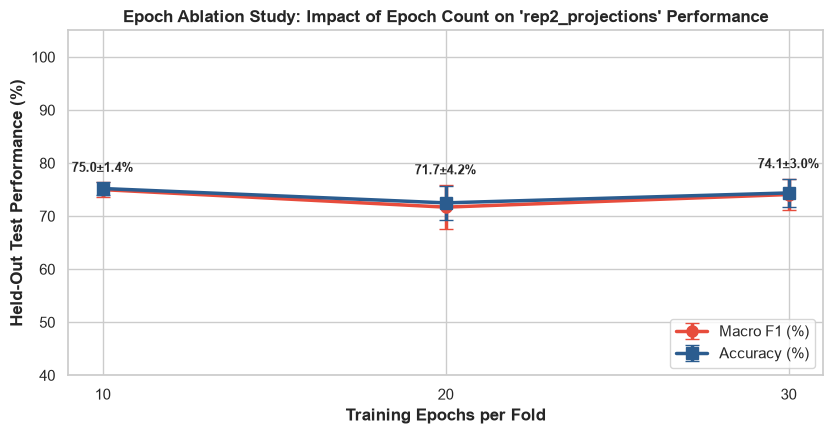

Saved epoch ablation plot image to: models\benchmarks\epoch_ablation_rep2_projections_curve.png


In [10]:
# Cell 5: Systematic Epoch Ablation Experiment (e.g. 10, 20, 30 Epochs)
print(f"\n=== Starting Epoch Ablation Study for Representation: '{REPRESENTATION}' ===")
epoch_candidates = [10, 20, 30]
ablation_results = {}

for ep_val in epoch_candidates:
    print(f"\n---> Evaluating Epoch Count = {ep_val} (num_runs={num_runs}) <---")
    ep_out_path = Path(f"models/benchmarks/epoch_ablation_{REPRESENTATION}_{ep_val}ep.json")
    ep_res = run_loso_cross_validation(
        rep_key=REPRESENTATION,
        epochs=ep_val,
        lr=lr,
        batch_size=batch_size,
        num_runs=num_runs,
        use_wandb=use_wandb,
        save_benchmark=True,
        output_json_path=ep_out_path
    )
    ablation_results[ep_val] = ep_res["test_metrics"]

# Master Epoch Ablation JSON Export
epoch_summary_path = Path(f"models/benchmarks/epoch_ablation_{REPRESENTATION}_summary.json")
with open(epoch_summary_path, "w", encoding="utf-8") as f:
    json.dump(ablation_results, f, indent=4)
print(f"\nSaved epoch ablation summary JSON to: {epoch_summary_path}")

# Plot Epoch Ablation Curves (Accuracy & Macro F1 vs Epochs with Error Bands)
ep_list = sorted(list(ablation_results.keys()))
f1_means = [ablation_results[ep]["macro_f1"] * 100 for ep in ep_list]
f1_stds = [ablation_results[ep]["macro_f1_std"] * 100 for ep in ep_list]
acc_means = [ablation_results[ep]["accuracy"] * 100 for ep in ep_list]
acc_stds = [ablation_results[ep]["accuracy_std"] * 100 for ep in ep_list]

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=100)
ax.errorbar(ep_list, f1_means, yerr=f1_stds, fmt='-o', color='#e74c3c', label='Macro F1 (%)', capsize=5, lw=2.5, ms=8)
ax.errorbar(ep_list, acc_means, yerr=acc_stds, fmt='-s', color='#2b5c8f', label='Accuracy (%)', capsize=5, lw=2.5, ms=8)
ax.set_xticks(ep_list)
ax.set_xlabel("Training Epochs per Fold", fontweight="bold")
ax.set_ylabel("Held-Out Test Performance (%)", fontweight="bold")
ax.set_title(f"Epoch Ablation Study: Impact of Epoch Count on '{REPRESENTATION}' Performance", fontweight="bold")
ax.set_ylim([40, 105])
ax.legend(loc="lower right")

for ep, f1_m, f1_s in zip(ep_list, f1_means, f1_stds):
    ax.annotate(f"{f1_m:.1f}±{f1_s:.1f}%", xy=(ep, f1_m + f1_s + 2), ha="center", fontweight="bold", fontsize=9)

plt.tight_layout()
ablation_fig_path = Path(f"models/benchmarks/epoch_ablation_{REPRESENTATION}_curve.png")
plt.savefig(ablation_fig_path, dpi=300)
plt.show()
print(f"Saved epoch ablation plot image to: {ablation_fig_path}")
